# AI Collaborative Filtering


In [1]:
import os
import json
import glob
import shutil
from datetime import datetime
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm import tqdm
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.parquet as pq
import torch
import torch.nn as nn
from torch.utils.data import IterableDataset, DataLoader
 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## 1. Class Config
Tuyệt đối không hardcode. Toàn bộ thông số truyền từ đây.


In [2]:
class Config:
    # Paths
    DATA_DIR = Path("../data")
    FINAL_DATA_DIR = DATA_DIR / "final_data"
    ARTIFACT_DIR = DATA_DIR / "artifacts"
    CF_DIR = ARTIFACT_DIR / "cf"
    PARQUET_DIR = DATA_DIR / "interactions_parquet"
    
    RATINGS_PATH = FINAL_DATA_DIR / "ratings_filtered_by_movie.csv" 
    
    
    # Data Schema
    USER_COL = "userId"
    MOVIE_COL = "movieId"
    RATING_COL = "rating"
    TIMESTAMP_COL = "timestamp"
    
    # Lọc và Chia tập (Top N mới nhất)
    MAX_ROWS_TO_PROCESS = 500_000 # max số dòng mới nhất
    TRAIN_RATIO = 0.8
    VAL_RATIO = 0.1
    TEST_RATIO = 0.1
    
    # Hyperparameters
    EMBEDDING_DIM = 64
    INIT_STD = 0.01
    BATCH_SIZE = 1024 
    CHUNK_SIZE = 500000 
    EPOCHS = 10
    LEARNING_RATE = 0.002
    WEIGHT_DECAY = 1e-4
    DROPOUT_RATE = 0.2
    
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    
    # Tiền tố Versioning bằng Timestamp
    RUN_TIMESTAMP = f"{datetime.now().strftime('%Y%m%d_%H%M%S')}_{500_000}"
    
    TOP_K = 10  # Số lượng đề xuất hàng đầu cho mỗi người dùng
    
    @classmethod
    def setup(cls):
        cls.PARQUET_DIR.mkdir(parents=True, exist_ok=True)
        cls.CF_DIR.mkdir(parents=True, exist_ok=True)
        (cls.PARQUET_DIR / "train").mkdir(exist_ok=True)
        (cls.PARQUET_DIR / "val").mkdir(exist_ok=True)
        (cls.PARQUET_DIR / "test").mkdir(exist_ok=True)
        print(f"[INFO] Target Device: {cls.DEVICE}")
        print(f"[INFO] Training Run ID: {cls.RUN_TIMESTAMP}")

Config.setup()


[INFO] Target Device: cpu
[INFO] Training Run ID: 20261019_123202_500000


## 2. Tiền xử lý & Chia tập Dữ liệu
Lấy 2 triệu dòng mới nhất theo thời gian, cắt theo tỷ lệ 0.8 / 0.1 / 0.1


In [3]:
class DataPreprocessor:
    def __init__(self, 
                 csv_path, 
                 user_col,
                 movie_col, 
                 rating_col, 
                 timestamp_col, 
                 max_rows,
                 chunk_size, 
                 train_ratio, 
                 val_ratio, 
                 test_ratio, 
                 num_test_per_user,
                 num_val_per_user,
                 parquet_dir
    ):
        self.csv_path = csv_path
        self.user_col = user_col
        self.movie_col = movie_col
        self.rating_col = rating_col
        self.timestamp_col = timestamp_col
        self.max_rows = max_rows
        self.chunk_size = chunk_size
        self.train_ratio = train_ratio
        self.val_ratio = val_ratio
        self.test_ratio = test_ratio
        self.num_test_per_user = num_test_per_user
        self.num_val_per_user = num_val_per_user
        self.parquet_dir = parquet_dir
        
    def process_and_split(self):
        print("[INFO] Đang tìm Top K tương tác mới nhất (Sort theo Timestamp)...")
        top_k_df = pd.DataFrame()
        
        # Đọc theo chunk và giữ lại các dòng mới nhất để tránh nổ RAM
        for chunk in pd.read_csv(self.csv_path, usecols=[self.user_col, self.movie_col, self.rating_col, self.timestamp_col], chunksize=self.chunk_size):
            top_k_df = pd.concat([top_k_df, chunk])
            # Giữ lại top max_rows theo timestamp giảm dần
            top_k_df = top_k_df.sort_values(self.timestamp_col, ascending=False).head(self.max_rows)
            
        print(f"[INFO] Đã trích xuất {len(top_k_df)} dòng tương tác mới nhất.")
        
        # Ánh xạ UUID -> Integer Index
        user_mapping = {str(u): i for i, u in enumerate(top_k_df[self.user_col].unique())}
        movie_mapping = {str(m): i for i, m in enumerate(top_k_df[self.movie_col].unique())}
        
        top_k_df["user_idx"] = top_k_df[self.user_col].astype(str).map(user_mapping)
        top_k_df["movie_idx"] = top_k_df[self.movie_col].astype(str).map(movie_mapping)
        
        # Xáo trộn trước khi chia tập
        top_k_df = top_k_df.sample(frac=1.0, random_state=42).reset_index(drop=True)
        
        n_total = len(top_k_df)
        n_train = int(n_total * self.train_ratio)
        n_val = int(n_total * self.val_ratio)
        
        # train_df = top_k_df.iloc[:n_train]
        # val_df = top_k_df.iloc[n_train:n_train+n_val]
        # test_df = top_k_df.iloc[n_train+n_val:]
        
        # chia tập theo user
        def split_by_user(df, num_test=5, num_val=5):
            user_groups = df.groupby("user_idx")
            train_list, val_list, test_list = [], [], []
            
            for user_id, group in user_groups:
                n_user = len(group)
                n_train_user = n_user - num_val - num_test
                
                # Sắp xếp theo timestamp giảm dần
                sorted_group = group.sort_values(self.timestamp_col, ascending=True)
                
                
                # nếu train ít hơn 10 thì chỉ lấy train
                if n_train_user < 10:
                    train_list.append(group)
                    continue
                
                train_list.append(sorted_group.iloc[:n_train_user])
                val_list.append(sorted_group.iloc[n_train_user:n_train_user+num_val])
                test_list.append(sorted_group.iloc[n_train_user+num_val:])
                
            return pd.concat(train_list), pd.concat(val_list), pd.concat(test_list)
        
        # Xóa các file cũ và Ghi ra Parquet theo thư mục
        for f in glob.glob(f"{self.parquet_dir}/*/*.parquet"): os.remove(f)
        
        train_df, val_df, test_df = split_by_user(
            top_k_df, 
            num_test=self.num_test_per_user, 
            num_val=self.num_val_per_user
        )
        
        train_df.to_parquet(self.parquet_dir / "train" / "data.parquet", index=False)
        val_df.to_parquet(self.parquet_dir / "val" / "data.parquet", index=False)
        test_df.to_parquet(self.parquet_dir / "test" / "data.parquet", index=False)
        
        print(f"[INFO] Đã chia tập thành công. Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
        return user_mapping, movie_mapping


## 3. DataLoader LazyLoading & Model CF


In [4]:
import math


class LazyParquetDataset(IterableDataset):
    def __init__(self, parquet_files, batch_size, rating_col):
        self.parquet_files = parquet_files
        self.batch_size = batch_size
        self.rating_col = rating_col

    def __iter__(self):
        for file_path in self.parquet_files:
            parquet_file = pq.ParquetFile(file_path)
            for batch in parquet_file.iter_batches(batch_size=self.batch_size):
                df = batch.to_pandas()
                users = torch.tensor(df["user_idx"].values, dtype=torch.long)
                movies = torch.tensor(df["movie_idx"].values, dtype=torch.long)
                ratings = torch.tensor(df[self.rating_col].values, dtype=torch.float32)
                yield users, movies, ratings
                
    def __len__(self):
        total_rows = sum(pq.ParquetFile(f).metadata.num_rows for f in self.parquet_files)
        # return total_rows // self.batch_size
        return math.ceil(total_rows / self.batch_size)

class CollaborativeFilteringModel(nn.Module):
    def __init__(self, num_users: int, num_movies: int, embedding_dim: int, init_std: float, dropout_param: float = 0.1):
        super().__init__()
        self.user_embedding = nn.Embedding(num_users, embedding_dim)
        self.movie_embedding = nn.Embedding(num_movies, embedding_dim)
        self.user_bias = nn.Embedding(num_users, 1)
        self.movie_bias = nn.Embedding(num_movies, 1)
        self.global_bias = nn.Parameter(torch.zeros(1))
        
        self.dropout = nn.Dropout(p=dropout_param)
        
        # Lưu ngưỡng rating tối thiểu và tối đa
        self.min_rating = 0.5
        self.max_rating = 5.0
        
        nn.init.normal_(self.user_embedding.weight, std=init_std)
        nn.init.normal_(self.movie_embedding.weight, std=init_std)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.movie_bias.weight)
        
        
    
    def forward(self, user_ids, movie_ids):
        # dropout được áp dụng cho embedding để giảm overfitting
        u_emb = self.dropout(self.user_embedding(user_ids))
        m_emb = self.dropout(self.movie_embedding(movie_ids))
        
        dot_product = (u_emb * m_emb).sum(dim=1)
        u_bias = self.user_bias(user_ids).squeeze()
        m_bias = self.movie_bias(movie_ids).squeeze()
        
        # Tổng tuyến tính ban đầu (raw prediction)
        raw_pred = dot_product + u_bias + m_bias + self.global_bias
        
        # Dùng Sigmoid co giãn để ép giá trị nằm đúng trong đoạn [min_rating, max_rating]
        rating_range = self.max_rating - self.min_rating
        pred = rating_range * torch.sigmoid(raw_pred) + self.min_rating
        return pred


## 4. Trainer (Có Logs, Val Loss, Metrics Track)


In [5]:
class ModelTrainer:
    def __init__(
        self, 
        model: nn.Module, 
        train_loader: DataLoader, 
        val_loader: DataLoader, 
        device: torch.device, 
        learning_rate: float, 
        weight_decay: float, 
        dropout_rate: float,
        epochs: int, 
        save_model_path: Path, 
        save_metrics_path: Path
    ):
        self.device = device
        self.model = model.to(self.device)
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.train_size = self._get_dataset_size(train_loader)
        self.val_size = self._get_dataset_size(val_loader)
        self.epochs = epochs
        self.save_model_path = save_model_path
        self.save_metrics_path = save_metrics_path
        
        self.criterion = nn.MSELoss()
        self.optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
        self.history = {"train_loss": [], "val_loss": [], "epochs": []}
        self.dropout_rate = dropout_rate
        
        self.config_dict = {
            "device": str(self.device),
            "train_size": self.train_size,
            "val_size": self.val_size,
            "epochs": self.epochs,
            "save_model_path": str(self.save_model_path),
            "dropout_rate": self.dropout_rate,
            "num_users": self.model.user_embedding.num_embeddings,
            "num_movies": self.model.movie_embedding.num_embeddings,
            "embedding_dim": self.model.user_embedding.embedding_dim,
            "init_std": self.model.user_embedding.weight.std().item(),
        }
        print(f"[INFO] Cấu hình mô hình: {json.dumps(self.config_dict, indent=4)}")
        
    def train(self):
        print(f"\n[INFO] Bắt đầu huấn luyện...")
        for epoch in range(1, self.epochs + 1):
            # 1. Train
            self.model.train()
            train_loss, train_samples = 0, 0
            
            progress_bar = tqdm(self.train_loader, desc=f"Epoch {epoch} [Train]")
            for users, movies, ratings in progress_bar:
                users, movies, ratings = users.to(self.device), movies.to(self.device), ratings.to(self.device)
                
                self.optimizer.zero_grad()
                preds = self.model(users, movies)
                loss = self.criterion(preds, ratings)
                loss.backward()
                self.optimizer.step()
                
                train_loss += loss.item() * len(ratings)
                train_samples += len(ratings)
                progress_bar.set_postfix(MSE=f"{(train_loss/train_samples):.4f}")
                
            avg_train_loss = train_loss / train_samples
            
            # 2. Validation
            self.model.eval()
            avg_val_loss, _, _, _ = self.evaluate(self.val_loader, criterion=self.criterion, mode="val")
            
            print(f"Epoch {epoch}/{self.epochs} | Train MSE: {avg_train_loss:.4f} | Val MSE: {avg_val_loss:.4f}")
            self.history["train_loss"].append(avg_train_loss)
            self.history["val_loss"].append(avg_val_loss)
            self.history["epochs"].append(epoch)
            
        print(f"[INFO] Huấn luyện hoàn tất sau {self.epochs} epochs.")
            
        # Lưu Model và History Metrics
        self.save_model_and_metrics()
        
        return self.history
    
    # eval

    def evaluate(
        self,
        data_loader: DataLoader,
        criterion: nn.Module = nn.MSELoss(),
        mode: str = "test",
    ):
        self.model.eval()
        total_loss, total_samples = 0, 0

        # Các mảng để gom dữ liệu vẽ đồ thị và tính metric trên tập Test
        all_preds = []
        all_ratings = []
        test_metrics = {
            "mse": 0,
            "rmse": 0,
            "mae": 0,
            "r2_score": 0
        }

        with torch.no_grad():
            for users, movies, ratings in data_loader:
                users, movies, ratings = (
                    users.to(self.device),
                    movies.to(self.device),
                    ratings.to(self.device),
                )
                preds = self.model(users, movies)
                loss = criterion(preds, ratings)

                total_loss += loss.item() * len(ratings)
                total_samples += len(ratings)

                if mode == "test":
                    # Thu thập dữ liệu để tính toán metric nâng cao
                    all_preds.extend(preds.cpu().numpy().flatten())
                    all_ratings.extend(ratings.cpu().numpy().flatten())

        avg_loss = total_loss / total_samples if total_samples > 0 else 0

        if mode == "val":
            print(f"[INFO] Validation MSE: {avg_loss:.4f}")
            return avg_loss, test_metrics, all_preds, all_ratings

        elif mode == "test":
            # Chuyển thành numpy array để xử lý bằng sklearn
            all_preds = np.array(all_preds)
            all_ratings = np.array(all_ratings)

            # 1. Tính toán các tiêu chí hồi quy
            mse = mean_squared_error(all_ratings, all_preds)
            rmse = np.sqrt(mse)
            mae = mean_absolute_error(all_ratings, all_preds)
            r2 = r2_score(all_ratings, all_preds)

            print("\n" + "=" * 30 + " TEST REPORT " + "=" * 30)
            print(f"1. Mean Squared Error (MSE)      : {mse:.4f}")
            print(f"2. Root Mean Squared Error (RMSE): {rmse:.4f} (Đoán lệch ~{rmse:.2f} sao)")
            print(f"3. Mean Absolute Error (MAE)     : {mae:.4f}")
            print(f"4. R-squared (R2 Score)          : {r2:.4f}")
            print("=" * 73 + "\n")

            # 2. Lưu các tiêu chí này vào file JSON để sau này đọc lại
            # self.history["test_metrics"] = {
            #     "mse": float(mse),
            #     "rmse": float(rmse),
            #     "mae": float(mae),
            #     "r2_score": float(r2),
            # }
            self.history["test_metrics"] = {
                "mse": float(mse),
                "rmse": float(rmse),
                "mae": float(mae),
                "r2_score": float(r2),
            }
            test_metrics = {
                "mse": float(mse),
                "rmse": float(rmse),
                "mae": float(mae),
                "r2_score": float(r2),
            }
            self.save_model_and_metrics()

            # (Tùy chọn) Vẽ thêm đồ thị phân phối sai số Actual vs Predicted như đã đề cập ở câu trước
            # self.plot_test_evaluation(all_ratings, all_preds)

            return mse, test_metrics, all_preds, all_ratings

    def _get_dataset_size(self, loader: DataLoader):
        """Hàm phụ trợ để đếm tổng số lượng mẫu (samples) trong một DataLoader."""
        total_samples = 0
        if loader is None:
            return 0
        for batch in loader:
            # batch thường trả về tuple (users, movies, ratings), phần tử cuối hoặc đầu định hình số lượng mẫu
            ratings = batch[2] 
            total_samples += len(ratings)
        return total_samples

    # save model and metrics
    def save_model_and_metrics(self):
        if not self.save_model_path.parent.exists():
            raise FileNotFoundError(f"[ERROR] Thư mục lưu mô hình không tồn tại: {self.save_model_path.parent}")
        
        torch.save(self.model.state_dict(), self.save_model_path)
        
        config_and_metrics = {
            "config": self.config_dict,
            "history": self.history
        }
        with open(self.save_metrics_path, "w", encoding="utf-8") as f:
            json.dump(config_and_metrics, f, indent=4)
        print(f"[INFO] Đã lưu mô hình và file metrics thành công tại {self.save_model_path.parent}")

## 5. Visualizer & Recommendation Client


In [6]:
class ResultVisualizer:
    @staticmethod
    def plot_history(history, save_plot_path):
        if not history or 'train_loss' not in history or 'val_loss' not in history:
            raise ValueError("[ERROR] Dữ liệu lịch sử huấn luyện không hợp lệ hoặc thiếu.")
        plt.figure(figsize=(10, 6))
        plt.plot(history['epochs'], history['train_loss'], label='Train Loss (MSE)', marker='o', color='blue')
        plt.plot(history['epochs'], history['val_loss'], label='Validation Loss (MSE)', marker='s', color='orange')
        plt.title('Quá trình huấn luyện Lọc cộng tác (Train vs Val)')
        plt.xlabel('Epochs')
        plt.ylabel('MSE Loss')
        plt.legend()
        plt.grid(True)
        plt.savefig(save_plot_path)
        plt.show()
        print(f"[INFO] Đã lưu biểu đồ thành công tại {save_plot_path}")
        
    # visualize loss train, val, test
    @staticmethod
    def plot_loss_train_val_test(train_loss, val_loss, test_loss, save_plot_path):
        plt.figure(figsize=(10, 6))
        plt.plot(train_loss, label='Train Loss (MSE)', marker='o', color='blue')
        plt.plot(val_loss, label='Validation Loss (MSE)', marker='s', color='orange')
        plt.plot(test_loss, label='Test Loss (MSE)', marker='d', color='green')
        plt.title('Quá trình huấn luyện Lọc cộng tác (Train vs Val vs Test)')
        plt.xlabel('Epochs')
        plt.ylabel('MSE Loss')
        plt.legend()
        plt.grid(True)
        plt.savefig(save_plot_path)
        plt.show()
        print(f"[INFO] Đã lưu biểu đồ thành công tại {save_plot_path}")

class RecommendationClient:
    def __init__(self, model_path, mapping_path, num_users, num_movies, embedding_dim, init_std, device):
        self.device = device
        
        mapping_df = pd.read_parquet(mapping_path)
        users_df = mapping_df[mapping_df['type'] == 'user']
        movies_df = mapping_df[mapping_df['type'] == 'movie']
        
        self.user_to_idx = dict(zip(users_df['id'].astype(str), users_df['idx']))
        self.movie_to_idx = dict(zip(movies_df['id'].astype(str), movies_df['idx']))
        self.idx_to_movie = {v: k for k, v in self.movie_to_idx.items()}
        
        self.model: CollaborativeFilteringModel = CollaborativeFilteringModel(num_users, num_movies, embedding_dim, init_std)
        self.model.load_state_dict(torch.load(model_path, map_location=self.device))
        self.model.to(self.device)
        self.model.eval()
        
    # def recommend(self, user_id: str, top_k: int = 10):
    #     user_id = str(user_id)
    #     if user_id not in self.user_to_idx:
    #         return f"[CẢNH BÁO] Không tìm thấy user ID {user_id}"
            
    #     u_idx = self.user_to_idx[user_id]
    #     u_tensor = torch.tensor([u_idx] * len(self.movie_to_idx), dtype=torch.long).to(self.device)
    #     m_tensor = torch.tensor(list(self.movie_to_idx.values()), dtype=torch.long).to(self.device)
        
    #     with torch.no_grad():
    #         predictions = self.model(u_tensor, m_tensor)
            
    #     top_k_indices = torch.topk(predictions, top_k).indices.cpu().numpy()
    #     return [{"movieId": self.idx_to_movie[idx], "score": float(predictions[idx])} for idx in top_k_indices]


    # top k: recommendation_ids, scores
    def recommend(self, user_idx, k=10) -> tuple[np.ndarray, np.ndarray]:
        self.model.eval()
        with torch.no_grad():
            # Lấy trực tiếp kích thước chuẩn từ Embedding layer của model đã train
            num_users = self.model.user_embedding.num_embeddings
            num_movies = self.model.movie_embedding.num_embeddings
            
            # Kiểm tra phòng hờ nếu user_idx vượt quá tập train (Cold Start)
            if user_idx >= num_users:
                return np.array([], dtype=np.int32), np.array([], dtype=np.float32)
            
            # Tạo tensor cho user hiện tại và toàn bộ dải index phim hợp lệ [0 -> num_movies - 1]
            u_tensor = torch.tensor([user_idx] * num_movies, dtype=torch.long).to(self.device)
            m_tensor = torch.arange(num_movies, dtype=torch.long).to(self.device)
            
            # Forward qua model PyTorch
            predictions = self.model(u_tensor, m_tensor)
            
            # Lấy top k index có điểm số dự đoán cao nhất
            top_k_tensor = torch.topk(predictions, min(k, num_movies))
            top_k_indices = top_k_tensor.indices.cpu().numpy()
            scores = top_k_tensor.values.cpu().numpy()
            
        return top_k_indices, scores
        

## 6. Thực thi Toàn bộ Hệ thống (Chỉ cần Run Ô này)


,userId,movieId,rating,timestamp,datetime
count,5.617578e+06,5.617578e+06,5.617578e+06,5.617578e+06,5617578
mean,1.417467e+05,5.061878e+03,3.523338e+00,1.129827e+09,2005-10-20 16:50:21
min,1.000000e+00,5.000000e+00,5.000000e-01,8.228736e+08,1996-01-29 00:00:00
25%,7.099400e+04,5.080000e+02,3.000000e+00,9.536719e+08,2000-03-21 20:51:39
50%,1.419470e+05,1.479000e+03,3.500000e+00,1.108962e+09,2005-02-21 04:52:52
75%,2.123070e+05,2.539000e+03,4.000000e+00,1.290309e+09,2010-11-21 03:07:37
max,2.832280e+05,1.937170e+05,5.000000e+00,1.537945e+09,2018-09-26 06:58:43
std,8.168616e+04,1.455435e+04,1.072849e+00,2.109987e+08,NaN


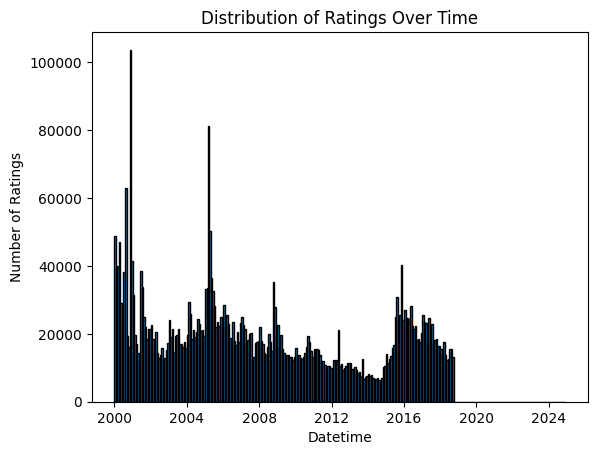

In [7]:
from datetime import datetime

rating_df = pd.read_csv(Config.RATINGS_PATH)

# parse datetime from timestamp
rating_df['datetime'] = pd.to_datetime(rating_df[Config.TIMESTAMP_COL], unit='s')
rating_df = rating_df.sort_values(by='datetime', ascending=False)
display(rating_df.describe())

# distribution of ratings
rating_df = rating_df[rating_df['datetime'] > '2000-01-01']  # filter out ratings before 2000
rating_counts = rating_df['datetime'].value_counts().sort_index()
bins = [datetime(year, month, 1) for year in range(2000, 2025) for month in range(1, 13)]
plt.hist(rating_df['datetime'], bins=bins, edgecolor='black')
plt.title("Distribution of Ratings Over Time")
plt.xlabel("Datetime")
plt.ylabel("Number of Ratings")
plt.show()

# display(f"Min Timestamp: {datetime.fromtimestamp(min_timestamp)} | Max Timestamp: {datetime.fromtimestamp(max_timestamp)}")

[INFO] Đang tìm Top K tương tác mới nhất (Sort theo Timestamp)...
[INFO] Đã trích xuất 500000 dòng tương tác mới nhất.
[INFO] Đã chia tập thành công. Train: 432590 | Val: 33705 | Test: 33705
[INFO] Cấu hình mô hình: {
    "device": "cpu",
    "train_size": 432590,
    "val_size": 33705,
    "epochs": 10,
    "save_model_path": "..\\data\\artifacts\\cf\\20261019_123202_500000\\20261019_123202_500000_cf_model.pt",
    "dropout_rate": 0.2,
    "num_users": 31109,
    "num_movies": 2433,
    "embedding_dim": 64,
    "init_std": 0.010005371645092964
}

[INFO] Bắt đầu huấn luyện...


Epoch 1 [Train]: 100%|██████████| 423/423 [00:07<00:00, 57.43it/s, MSE=1.2219]


[INFO] Validation MSE: 1.0254
Epoch 1/10 | Train MSE: 1.2219 | Val MSE: 1.0254


Epoch 2 [Train]: 100%|██████████| 423/423 [00:13<00:00, 32.23it/s, MSE=0.9777]


[INFO] Validation MSE: 0.9849
Epoch 2/10 | Train MSE: 0.9777 | Val MSE: 0.9849


...

[INFO] Validation MSE: 0.7762
Epoch 8/10 | Train MSE: 0.6860 | Val MSE: 0.7762


Epoch 9 [Train]: 100%|██████████| 423/423 [00:12<00:00, 33.20it/s, MSE=0.6652]


[INFO] Validation MSE: 0.7731
Epoch 9/10 | Train MSE: 0.6652 | Val MSE: 0.7731


Epoch 10 [Train]: 100%|██████████| 423/423 [00:13<00:00, 31.97it/s, MSE=0.6503]


[INFO] Validation MSE: 0.7669
Epoch 10/10 | Train MSE: 0.6503 | Val MSE: 0.7669
[INFO] Huấn luyện hoàn tất sau 10 epochs.
[INFO] Đã lưu mô hình và file metrics thành công tại ..\data\artifacts\cf\20261019_123202_500000


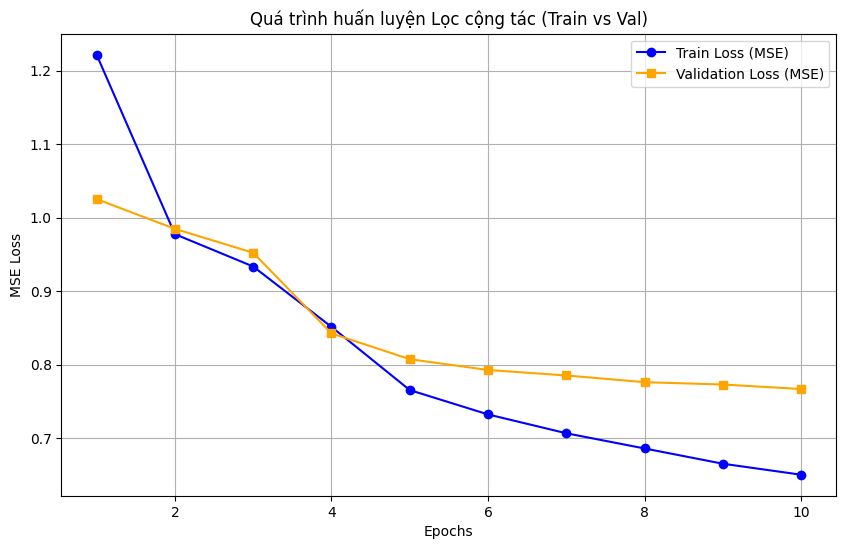

[INFO] Đã lưu biểu đồ thành công tại ..\data\artifacts\cf\20261019_123202_500000\20261019_123202_500000_history_loss_chart.png


In [8]:
# A. Khởi tạo đường dẫn động (Version bằng Timestamp)
dir_path_with_timestamp: Path =  Config.CF_DIR / Config.RUN_TIMESTAMP
os.makedirs(dir_path_with_timestamp, exist_ok=True)

def get_timestamped_path(base_dir: Path, postfix_filename: str) -> Path:
    """
    Tạo đường dẫn tệp với tiền tố timestamp.
    
    Args:
        base_dir (Path): Thư mục cơ sở để lưu tệp.
        postfix_filename (str): Tên tệp gốc.
        
    Returns:
        Path: Đường dẫn tệp mới với tiền tố timestamp.
    """
    return base_dir / f"{Config.RUN_TIMESTAMP}_{postfix_filename}"

model_path: Path = get_timestamped_path(dir_path_with_timestamp, "bmf_model.pt")
metrics_path: Path = get_timestamped_path(dir_path_with_timestamp, "bmf_metrics.json")
history_plot_path: Path = get_timestamped_path(dir_path_with_timestamp, "bmf_history_loss.png")
mapping_path: Path = get_timestamped_path(dir_path_with_timestamp, "mappings.parquet")
# lost_plot_path: Path = get_timestamped_path(dir_path_with_timestamp, "loss_chart.png")


# B. Xử lý & Chia tập Dữ liệu
preprocessor = DataPreprocessor(
    csv_path=Config.RATINGS_PATH,
    user_col=Config.USER_COL,
    movie_col=Config.MOVIE_COL,
    rating_col=Config.RATING_COL,
    timestamp_col=Config.TIMESTAMP_COL,
    max_rows=Config.MAX_ROWS_TO_PROCESS,
    chunk_size=Config.CHUNK_SIZE,
    train_ratio=Config.TRAIN_RATIO,
    val_ratio=Config.VAL_RATIO,
    test_ratio=Config.TEST_RATIO,
    num_test_per_user=5,
    num_val_per_user=5,
    parquet_dir=Config.PARQUET_DIR
)
user_mapping, movie_mapping = preprocessor.process_and_split()

# Lưu Mapping
users_df = pd.DataFrame(list(user_mapping.items()), columns=['id', 'idx'])
users_df['type'] = 'user'
movies_df = pd.DataFrame(list(movie_mapping.items()), columns=['id', 'idx'])
movies_df['type'] = 'movie'
pd.concat([users_df, movies_df], ignore_index=True).to_parquet(mapping_path, engine='pyarrow', index=False)

# C. Khởi tạo DataLoader
train_ds = LazyParquetDataset(glob.glob(f"{Config.PARQUET_DIR}/train/*.parquet"), Config.BATCH_SIZE, Config.RATING_COL)
val_ds = LazyParquetDataset(glob.glob(f"{Config.PARQUET_DIR}/val/*.parquet"), Config.BATCH_SIZE, Config.RATING_COL)

train_loader = DataLoader(train_ds, batch_size=None)
val_loader = DataLoader(val_ds, batch_size=None)

# D. Khởi tạo Model & Training
model_pt = CollaborativeFilteringModel(
    len(user_mapping), 
    len(movie_mapping), 
    Config.EMBEDDING_DIM, 
    Config.INIT_STD,
    dropout_param=Config.DROPOUT_RATE if hasattr(Config, 'DROPOUT_RATE') else 0.2
)

trainer = ModelTrainer(
    model=model_pt,
    train_loader=train_loader,
    val_loader=val_loader,
    device=Config.DEVICE,
    learning_rate=Config.LEARNING_RATE,
    weight_decay=Config.WEIGHT_DECAY,
    dropout_rate=Config.DROPOUT_RATE if hasattr(Config, 'DROPOUT_RATE') else 0.2,
    epochs=Config.EPOCHS,
    save_model_path=model_path,
    save_metrics_path=metrics_path
)

history = trainer.train()

# E. Hiển thị Biểu đồ Loss
ResultVisualizer.plot_history(history, history_plot_path)


## 7. Đánh giá Tập Test & Thử nghiệm Client (Evaluation)


In [9]:
# plot MSE, RMSE, MAE, R2 Score trên tập Test
def plot_test_evaluation(all_ratings, all_preds):
    plt.figure(figsize=(10, 6))
    plt.scatter(all_ratings, all_preds, alpha=0.5)
    plt.plot([all_ratings.min(), all_ratings.max()], [all_ratings.min(), all_ratings.max()], 'r--', lw=2)
    plt.title('Actual vs Predicted Ratings')
    plt.xlabel('Actual Ratings')
    plt.ylabel('Predicted Ratings')
    plt.grid(True)
    plt.show()


============================== TEST REPORT ==============================
1. Mean Squared Error (MSE)      : 0.8013
2. Root Mean Squared Error (RMSE): 0.8951 (Đoán lệch ~0.90 sao)
3. Mean Absolute Error (MAE)     : 0.6717
4. R-squared (R2 Score)          : 0.2926

[INFO] Đã lưu mô hình và file metrics thành công tại ..\data\artifacts\cf\20261019_123202_500000


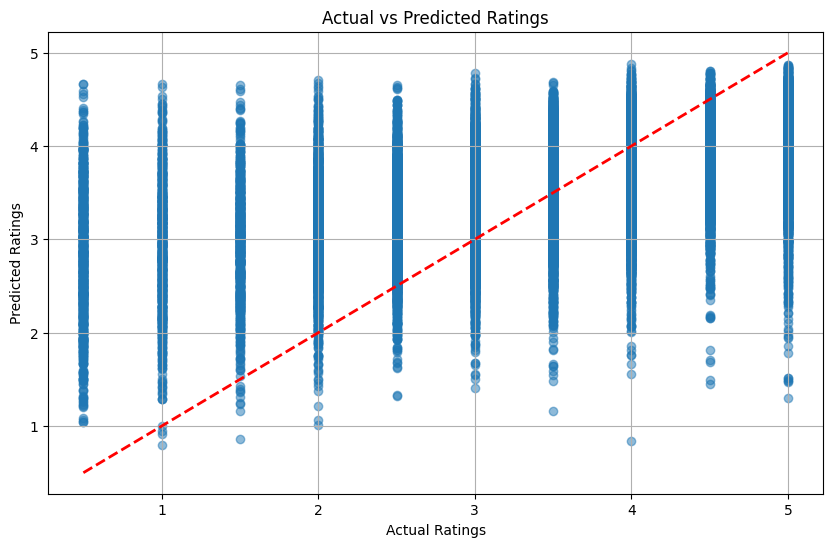

In [10]:
# A. Test Set Evaluation
test_ds = LazyParquetDataset(glob.glob(f"{Config.PARQUET_DIR}/test/*.parquet"), Config.BATCH_SIZE, Config.RATING_COL)
test_loader = DataLoader(test_ds, batch_size=None)

mse, test_metrics, all_preds, all_ratings = trainer.evaluate(test_loader, criterion=nn.MSELoss(), mode="test")
plot_test_evaluation(all_ratings, all_preds)

# B. Thử nghiệm Client với Model vừa train
client = RecommendationClient(model_path, mapping_path, len(user_mapping), len(movie_mapping), Config.EMBEDDING_DIM, Config.INIT_STD, Config.DEVICE)



## ALS model

In [11]:
# !pip install implicit

In [12]:
import implicit
from scipy.sparse import csr_matrix

train_df = pd.read_parquet(f"{Config.PARQUET_DIR}/train/data.parquet")
scores = train_df[Config.RATING_COL].values
user_idx = train_df["user_idx"].values
movie_idx = train_df["movie_idx"].values
# 1. Build ma trận sparse: hàng=user, cột=movie, giá trị=score (confidence)
# Đọc số lượng users/movies thực tế từ mapping để set kích thước cứng cho ma trận
mapping_df = pd.read_parquet(mapping_path)
num_users = len(mapping_df[mapping_df["type"] == "user"])
num_movies = len(mapping_df[mapping_df["type"] == "movie"])
matrix = csr_matrix((scores, (user_idx, movie_idx)), shape=(num_users, num_movies))

# 2. Train — KHÔNG có vòng lặp epoch/batch/optimizer.step() thủ công như PyTorch
model_als = implicit.als.AlternatingLeastSquares(
    factors=64,
    regularization=0.01,
    iterations=100,
    random_state=42, 
)
model_als.fit(matrix)   # toàn bộ việc "luân phiên giải" nằm gọn trong 1 dòng này


c:\Users\THUYEN\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\THUYEN\AppData\Local\Programs\Python\Python311\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 12 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()
100%|██████████| 100/100 [00:14<00:00,  6.75it/s]


In [13]:
# CŨ (SAI): dùng rating làm confidence
# matrix = csr_matrix((scores, (user_idx, movie_idx)))  # scores = 0.5..5

# MỚI (ĐÚNG): 
# Option A: binarize (implicit chuẩn)
#   matrix = (rating >= 3.5).astype(float)   # thích/không
# Option B (khuyến nghị): confidence = 1 + alpha * rating
#   NHƯNG implicit lib KHÔNG nhận confidence riêng — value chính là "độ mạnh"
#   → Binarize + weight bằng rating tương đối
#
# Đơn giản & đúng bản chất:
pos_mask = train_df[Config.RATING_COL] >= 3.5   # positive interactions
matrix = csr_matrix(
    (np.ones(pos_mask.sum()), 
     (train_df["user_idx"].values[pos_mask], train_df["movie_idx"].values[pos_mask])),
    shape=(num_users, num_movies)
)
# Hoặc weight = 1 + rating để vẫn giữ thông tin "thích bao nhiêu"
# (implicit lib coi đây là preference strength)

model_als = implicit.als.AlternatingLeastSquares(
    factors=64, regularization=0.05, alpha=20.0, iterations=30, random_state=42
)
model_als.fit(matrix)

100%|██████████| 30/30 [00:04<00:00,  7.16it/s]


In [14]:
# 3. Dùng
user_id = 5
recommendations = model_als.recommend(user_id, matrix[user_id], N=10)
user_vectors = model_als.user_factors   # lấy vector nếu cần
movie_vectors = model_als.item_factors

# display(recommendations)
# display(user_vectors)
# display(movie_vectors)

    
for i in range(5):
    user_id = np.random.choice(list(user_idx))
    print(f"User ID: {user_id}")
    print(f"Recommendations by SGD")
    recommendations = client.recommend(user_idx=user_id, k=Config.TOP_K)
    display(recommendations)
    
    print(f"Recommendations by Implicit")
    recommendations_implicit = model_als.recommend(user_id, matrix[user_id], N=Config.TOP_K)
    display(recommendations_implicit)

User ID: 30231
Recommendations by SGD


(array([ 35,  33,  62,  32,  23,  34, 346,   6, 366,  26]),
 array([4.6550107, 4.5092964, 4.4990554, 4.4877367, 4.4470544, 4.44215  ,
        4.423441 , 4.4210043, 4.4189544, 4.415302 ], dtype=float32))

Recommendations by Implicit


(array([387, 341, 353, 354, 359, 357, 355, 343, 289, 251], dtype=int32),
 array([0.64303   , 0.63072526, 0.55692565, 0.4528916 , 0.42728695,
        0.42020246, 0.40308452, 0.39482427, 0.39127153, 0.38900197],
       dtype=float32))

User ID: 13285
Recommendations by SGD


...

(array([350, 257,  16, 283, 343, 198, 363,  78,  72, 302], dtype=int32),
 array([0.52921563, 0.48440024, 0.4338904 , 0.43127817, 0.399166  ,
        0.38082516, 0.3655846 , 0.3649723 , 0.36366862, 0.36164424],
       dtype=float32))

User ID: 3681
Recommendations by SGD


(array([ 35,  32,  34,  48,  23,  62,  63, 179,  33, 313]),
 array([4.345887 , 4.198681 , 4.1865225, 4.1443295, 4.135377 , 4.1143575,
        4.0730305, 4.0559735, 4.0411067, 4.0264006], dtype=float32))

Recommendations by Implicit


(array([ 50, 202, 179, 238,  64, 323,  29,  11, 353, 330], dtype=int32),
 array([1.4704431, 1.3594961, 1.3478651, 1.2720644, 1.2476888, 1.2408624,
        1.2301979, 1.23019  , 1.1712117, 1.1692095], dtype=float32))

## Build Test

In [15]:
def recommend_pytorch(model: torch.nn.Module, user_idx: int, idx_to_movie: dict, device=Config.DEVICE, k=10):
    model.eval()
    with torch.no_grad():
        # Lấy trực tiếp kích thước chuẩn từ Embedding layer của model đã train
        num_users = model.user_embedding.num_embeddings
        num_movies = model.movie_embedding.num_embeddings
        
        # Kiểm tra phòng hờ nếu user_idx vượt quá tập train (Cold Start)
        if user_idx >= num_users:
            return np.array([], dtype=np.int32), np.array([], dtype=np.float32)
        
        # Tạo tensor cho user hiện tại và toàn bộ dải index phim hợp lệ [0 -> num_movies - 1]
        u_tensor = torch.tensor([user_idx] * num_movies, dtype=torch.long).to(device)
        m_tensor = torch.arange(num_movies, dtype=torch.long).to(device)
        
        # Forward qua model PyTorch
        predictions = model(u_tensor, m_tensor)
        
        # Lấy top k index có điểm số dự đoán cao nhất
        top_k_tensor = torch.topk(predictions, min(k, num_movies))
        top_k_indices = top_k_tensor.indices.cpu().numpy()
        scores = top_k_tensor.values.cpu().numpy()
        
    return top_k_indices, scores

In [16]:

class Evaluation:
    
    @staticmethod
    def evaluate_all(model , matrix, test_df: pd.DataFrame, k: int = 10, model_type='pytorch',) -> dict:
        user_ids = test_df["user_idx"].unique()
        rows = []
        movie_to_idx = test_df.set_index("movie_idx").to_dict()["movieId"]
        idx_to_movie = {v: k for k, v in movie_to_idx.items()}
        for user_id in user_ids:
            relevant_ids = set(test_df[test_df["user_idx"] == user_id]["movie_idx"].values)
            
            if model_type == 'pytorch':
                recommended_ids, scores = recommend_pytorch(
                    model=model,
                    user_idx=user_id,
                    idx_to_movie=idx_to_movie,
                    device=Config.DEVICE,
                    k=k
                )
            else:
                recommended_ids, scores = model.recommend(user_id, matrix[user_id], N=k)
            precision, recall = Evaluation.precision_recall_at_k(recommended_ids, relevant_ids, k)
            f1 = Evaluation.f1_at_k(precision, recall)
            hit_rate = Evaluation.hit_rate_at_k(recommended_ids, relevant_ids, k)
            ndcg = Evaluation.ndcg_at_k(recommended_ids, relevant_ids, k)
            mrr = Evaluation.mean_reciprocal_rank(recommended_ids, relevant_ids)
            map = Evaluation.mean_average_precision(recommended_ids, relevant_ids)
            rows.append({
                "user_id": user_id,
                "precision@k": precision,
                "recall@k": recall,
                "f1@k": f1,
                "hit_rate@k": hit_rate,
                "ndcg@k": ndcg,
                "mrr@k": mrr,
                "map@k": map, 
            })
            
        return {
            "k" : k,
            "precision@k": np.mean([r["precision@k"] for r in rows]),
            "recall@k": np.mean([r["recall@k"] for r in rows]),
            "f1@k": np.mean([r["f1@k"] for r in rows]),
            "hit_rate@k": np.mean([r["hit_rate@k"] for r in rows]),
            "ndcg@k": np.mean([r["ndcg@k"] for r in rows]),
            "mrr@k": np.mean([r["mrr@k"] for r in rows]),
            "map@k": np.mean([r["map@k"] for r in rows])
        }
        
    @staticmethod
    def mean_reciprocal_rank(recommended_ids: list, relevant_ids: set) -> float:
        for rank, movie_id in enumerate(recommended_ids):
            if movie_id in relevant_ids:
                return 1.0 / (rank + 1)
        return 0.0
    
    @staticmethod
    def mean_average_precision(recommended_ids: list, relevant_ids: set) -> float:
        hits = 0
        precision_sum = 0.0
        for rank, movie_id in enumerate(recommended_ids):
            if movie_id in relevant_ids:
                hits += 1
                precision_sum += hits / (rank + 1)
        return precision_sum / len(relevant_ids) if len(relevant_ids) > 0 else 0.0

    @staticmethod
    def ndcg_at_k(recommended_ids: list, relevant_ids: set, k: int) -> float:
        # DCG: cộng dồn, phim đúng càng ở vị trí đầu càng được tính điểm cao
        dcg = sum(
            1.0 / np.log2(rank + 2)           # rank bắt đầu từ 0 -> log2(2), log2(3)...
            for rank, movie_id in enumerate(recommended_ids[:k])
            if movie_id in relevant_ids
        )
        # IDCG: trường hợp LÝ TƯỞNG — toàn bộ phim đúng nằm NGAY ĐẦU danh sách
        ideal_hits = min(len(relevant_ids), k)
        idcg = sum(1.0 / np.log2(rank + 2) for rank in range(ideal_hits))
        return dcg / idcg if idcg > 0 else 0.0
    
    @staticmethod
    # def precision_recall_at_k(recommended_ids: list, true_id: int, k):
    #     # recommended_ids: list movie_id model gợi ý (top-K)
    #     # true_id: movie_id THẬT user đã tương tác (bị giấu lúc train)
        
    #     hit = 1 if true_id in recommended_ids[:k] else 0
    #     #     ^^^ đây chính là bước "check movie_id có nằm trong top-K không"
    #     #     KHÔNG kiểm tra score, chỉ kiểm tra ID có TRÙNG hay không
        
    #     return hit / k, hit

    @staticmethod
    def precision_recall_at_k(recommended_ids: list, true_ids: list, k):
        # true_ids giờ là 1 SET nhiều movie_id (vd 5 phim bị giấu)
        recommended_set = set(recommended_ids[:k])
        true_set = set(true_ids)
        
        hits = len(recommended_set & true_set)   # ĐẾM số ID TRÙNG giữa 2 tập
        
        precision = hits / k                      # hits / K
        recall = hits / len(true_set)              # hits / tổng số ground truth
        return precision, recall

    @staticmethod
    def f1_at_k(precision, recall):
        if precision + recall == 0:
            return 0.0
        return 2 * precision * recall / (precision + recall)

    @staticmethod
    def hit_rate_at_k(recommended_ids, relevant_ids, k):
        return 1.0 if set(recommended_ids[:k]) & relevant_ids else 0.0

In [17]:
test_df = pd.read_parquet(Config.PARQUET_DIR / "test" / "data.parquet")
display(test_df.head(10))
display(test_df.info())

,userId,movieId,rating,timestamp,user_idx,movie_idx
0,280481,1373,3.5,1537944689,0,4
1,280481,8961,1.0,1537944976,0,3
2,280481,2100,2.0,1537945078,0,2
3,280481,2294,2.0,1537945121,0,1
4,280481,2355,3.0,1537945123,0,0
5,273574,608,5.0,1520776434,1,63
6,273574,924,2.5,1526485453,1,179
7,273574,2791,5.0,1529179059,1,387
8,273574,122906,4.0,1537091145,1,79
9,273574,53000,3.5,1537944158,1,11


<class 'pandas.DataFrame'>
RangeIndex: 33705 entries, 0 to 33704
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   userId     33705 non-null  int64  
 1   movieId    33705 non-null  int64  
 2   rating     33705 non-null  float64
 3   timestamp  33705 non-null  int64  
 4   user_idx   33705 non-null  int64  
 5   movie_idx  33705 non-null  int64  
dtypes: float64(1), int64(5)
memory usage: 1.5 MB


None

In [18]:
eval_pt = Evaluation.evaluate_all(
    model=model_pt, 
    matrix=matrix, 
    test_df=test_df, 
    k=Config.TOP_K, 
    model_type='pytorch'
)
display(eval_pt)

{'k': 10,
 'precision@k': np.float64(0.02658359293873313),
 'recall@k': np.float64(0.05316718587746626),
 'f1@k': np.float64(0.0354447905849775),
 'hit_rate@k': np.float64(0.21450823319982198),
 'ndcg@k': np.float64(0.03975543078837703),
 'mrr@k': np.float64(0.06436277176152565),
 'map@k': np.float64(0.01678497844274435)}

In [19]:
eval_als = Evaluation.evaluate_all(
    model=model_als, 
    matrix=matrix, 
    test_df=test_df, 
    k=Config.TOP_K, 
    model_type='als'
)
display(eval_als)

{'k': 10,
 'precision@k': np.float64(0.050422785936804625),
 'recall@k': np.float64(0.10084557187360925),
 'f1@k': np.float64(0.06723038124907284),
 'hit_rate@k': np.float64(0.39415516985610444),
 'ndcg@k': np.float64(0.08387102220419357),
 'mrr@k': np.float64(0.15011114172217865),
 'map@k': np.float64(0.03866639352175623)}

In [20]:
evaluation_results = []
evaluation_results.append({
    "model_type": "pytorch",
    **eval_pt
})
evaluation_results.append({
    "model_type": "als",
    **eval_als
})

In [23]:
df_eval_results = pd.DataFrame(evaluation_results)
display(df_eval_results)



eval_results_path: Path = dir_path_with_timestamp / f"{Config.RUN_TIMESTAMP}_ bmf_als_evaluation_results.csv"
df_eval_results.to_csv(eval_results_path, index=False)
print(f"[INFO] Evaluation results saved to: {eval_results_path}")


,model_type,k,precision@k,recall@k,f1@k,hit_rate@k,ndcg@k,mrr@k,map@k
0,pytorch,10,0.026584,0.053167,0.035445,0.214508,0.039755,0.064363,0.016785
1,als,10,0.050423,0.100846,0.067230,0.394155,0.083871,0.150111,0.038666


[INFO] Evaluation results saved to: ..\data\artifacts\cf\20261019_123202_500000\20261019_123202_500000_ bmf_als_evaluation_results.csv


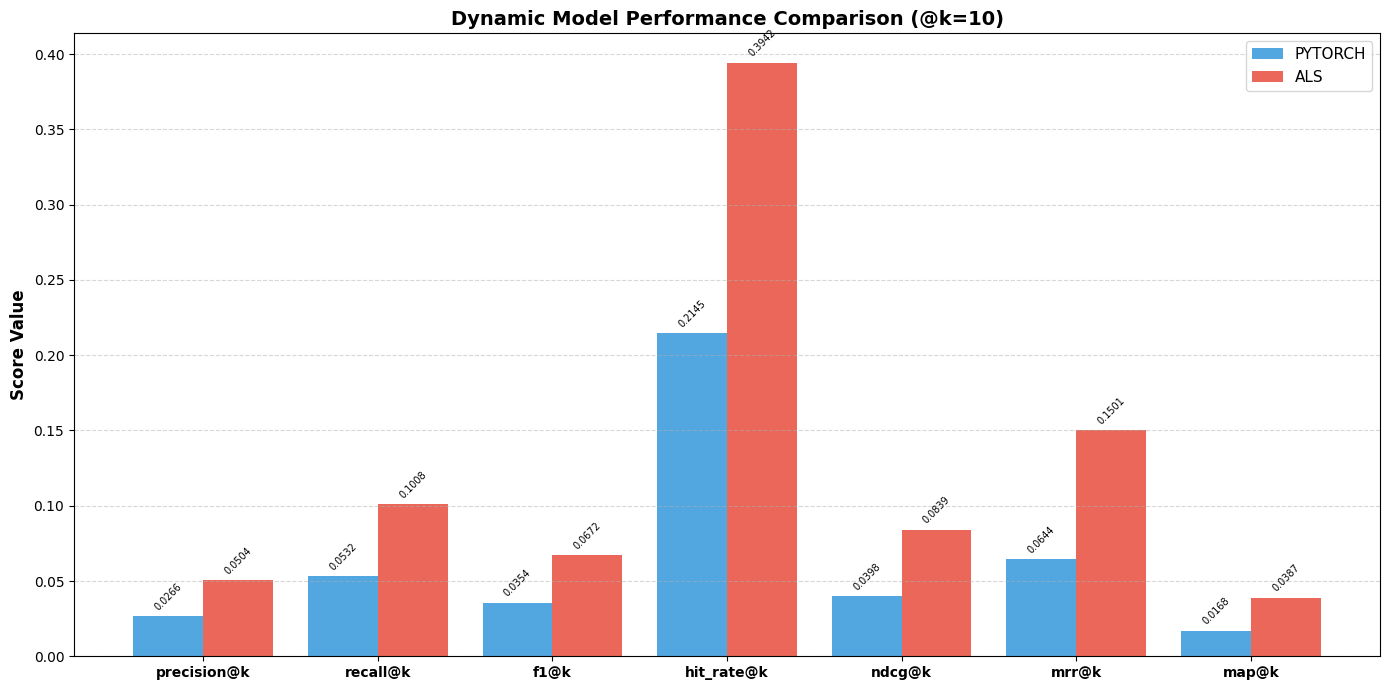

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Đọc dữ liệu từ file CSV đánh giá (thay 'evaluation_results.csv' bằng file thực tế của bạn)
df = pd.read_csv(eval_results_path)

# Tự động lấy danh sách metrics và các model từ file
metrics = [col for col in df.columns if col not in ['model_type', 'k']]
models = df['model_type'].tolist()

x = np.arange(len(metrics))
num_models = len(models)
total_width = 0.8  # Tổng bề ngang cho một cụm cột
width = total_width / num_models  # Tự chia bề ngang theo số lượng model

# Khởi tạo biểu đồ
fig, ax = plt.subplots(figsize=(14, 7))
rects_list = []
colors = ['#3498db', '#e74c3c', '#2ecc71', '#9b59b6', '#f1c40f', '#e67e22']

# 2. Vòng lặp vẽ cột động cho từng model
for i, model in enumerate(models):
  scores = df[df['model_type'] == model][metrics].values[0]
  offset = (i - num_models / 2 + 0.5) * width
  color = colors[i % len(colors)]

  rects = ax.bar(
      x + offset, scores, width, label=model.upper(), color=color, alpha=0.85
  )
  rects_list.append(rects)

# 3. Cấu hình giao diện biểu đồ
ax.set_ylabel('Score Value', fontsize=12, fontweight='bold')
ax.set_title(
    'Dynamic Model Performance Comparison (@k=10)',
    fontsize=14,
    fontweight='bold',
)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=10, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)


# 4. Hàm hiển thị giá trị chính xác trên mỗi cột
def autolabel(rects):
  for rect in rects:
    height = rect.get_height()
    if height > 0:
      ax.annotate(
          f'{height:.4f}',
          xy=(rect.get_x() + rect.get_width() / 2, height),
          xytext=(0, 3),
          textcoords='offset points',
          ha='center',
          va='bottom',
          fontsize=7,
          rotation=45,
      )


for rects in rects_list:
  autolabel(rects)

plt.tight_layout()
plt.savefig('dynamic_model_comparison.png', dpi=300)
plt.show()

# save the figure
fig.savefig(dir_path_with_timestamp / f"{Config.RUN_TIMESTAMP}_eval_results.png")

## Gửi thông báo telegram